In [ ]:
# step1_dataset
import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')

# 2. Tampilkan struktur data
print("=" * 60)
print("STRUKTUR DATASET")
print("=" * 60)
print(f"Jumlah baris : {df.shape[0]}")
print(f"Jumlah kolom : {df.shape[1]}")
print("\nTipe data tiap kolom:")
print(df.dtypes)

print("\nRingkasan statistik (numerik):")
print(df.describe().T)

# 3. Identifikasi fitur numerik untuk clustering
fitur_numerik = ['latitude', 'longitude', 'depth', 'mag', 'sig']
print("\nFitur numerik yang akan digunakan:", fitur_numerik)

<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\3043193006.py:6: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')


STRUKTUR DATASET
Jumlah baris : 10000
Jumlah kolom : 25

Tipe data tiap kolom:
id                           object
time                        float64
latitude                    float64
longitude                   float64
depth                       float64
mag                         float64
magType                      object
place                        object
status                       object
tsunami                       int64
sig                           int64
net                          object
nst                           int64
dmin                        float64
rms                         float64
gap                         float64
type                         object
title                        object
evidence_span                object
cot_rationale                object
magnitude_severity_class     object
focal_depth_regime           object
tsunami_hazard_potential     object
tectonic_boundary_zone       object
confidence_score            float64
dtype: object

Ringka

<>:7: SyntaxWarning: invalid escape sequence '\C'
<>:7: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\470934780.py:7: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')


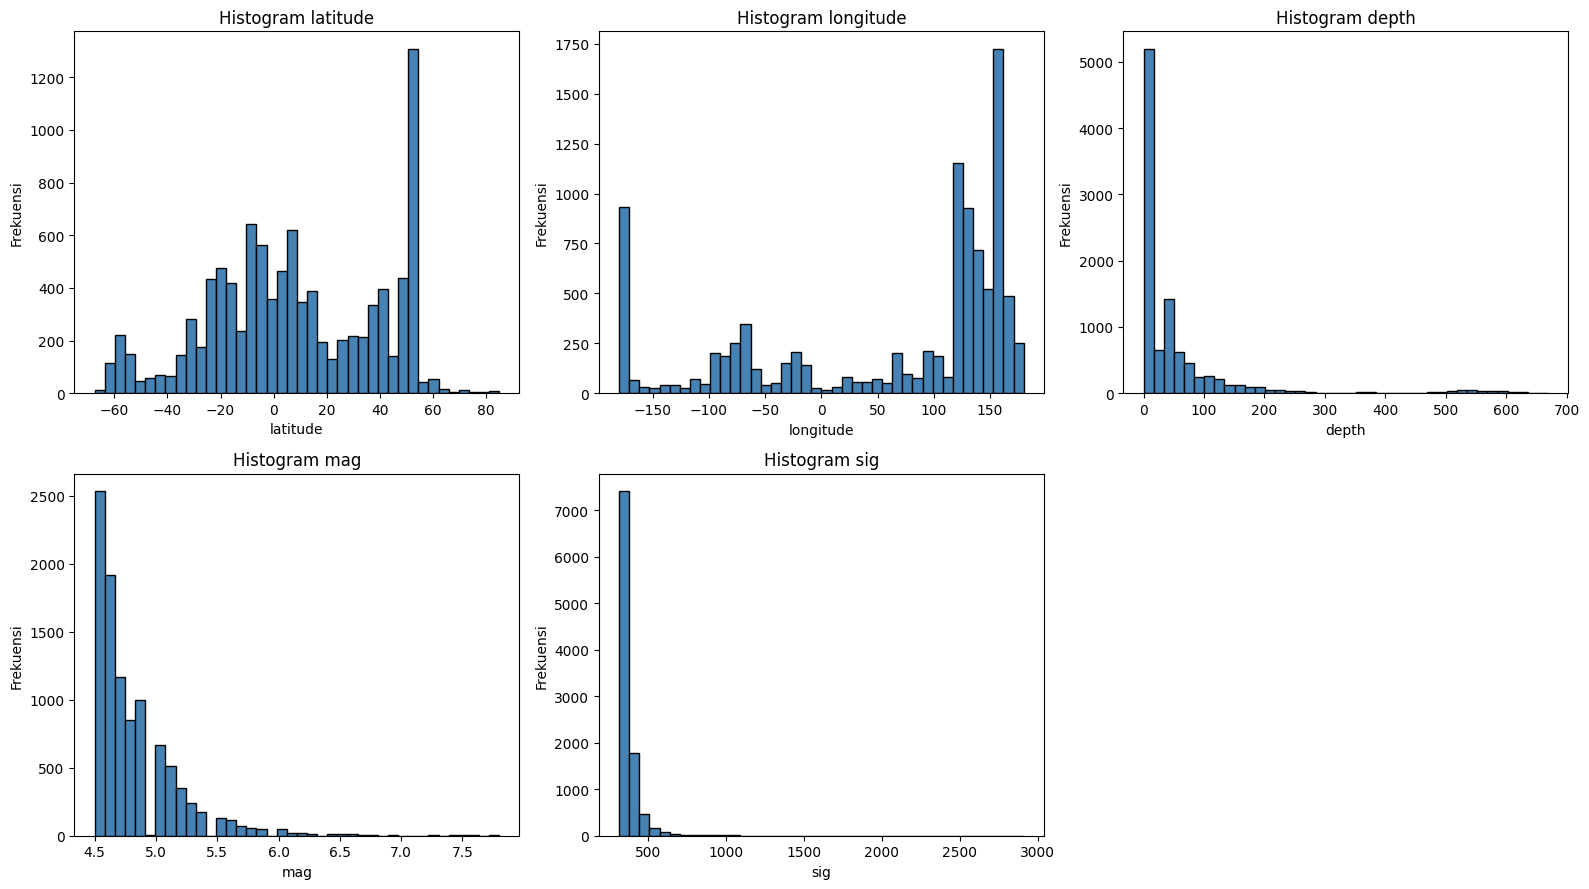

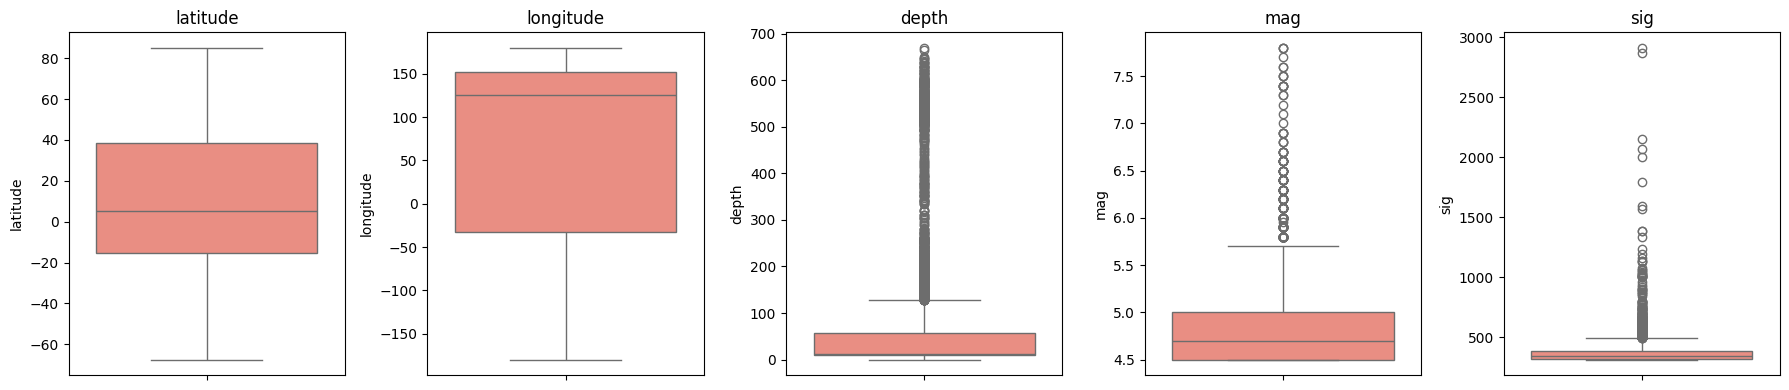

MISSING VALUES
latitude     0
longitude    0
depth        0
mag          0
sig          0
dtype: int64


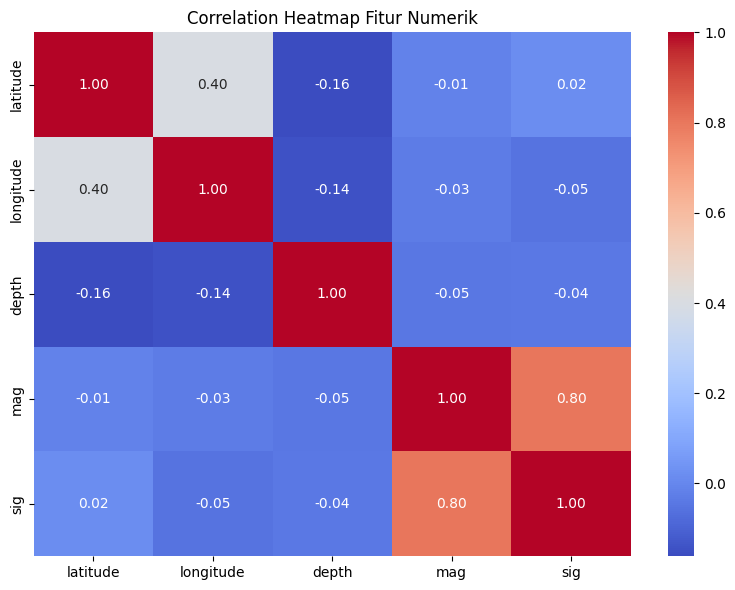

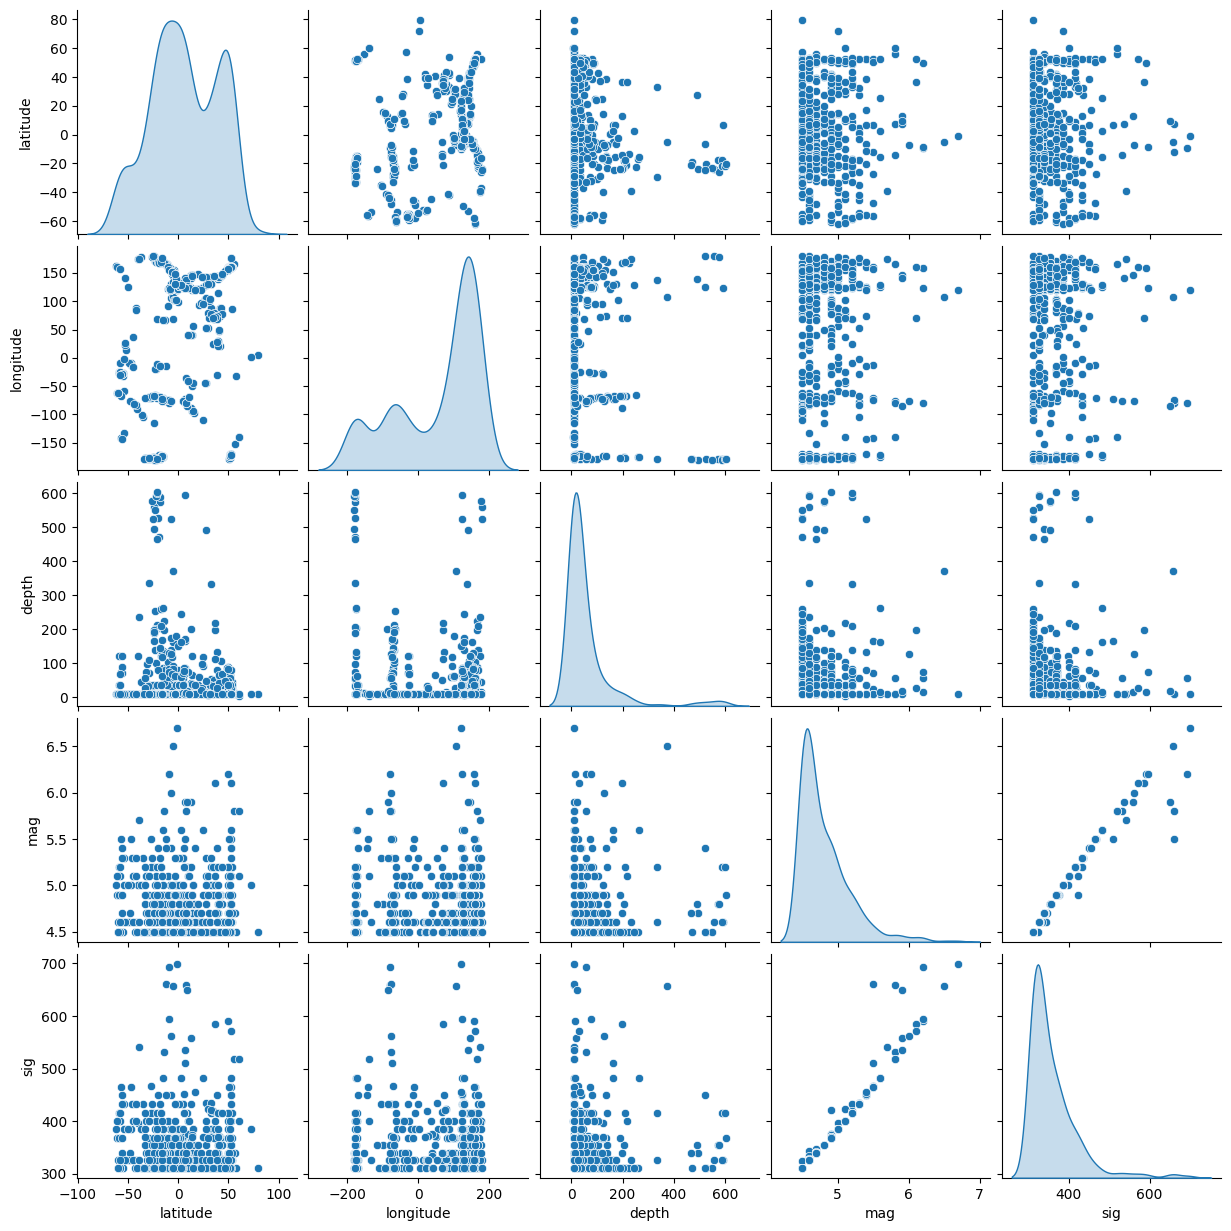

In [ ]:
# step2_eda
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')
fitur_numerik = ['latitude', 'longitude', 'depth', 'mag', 'sig']

# ---------- 2.1 Distribusi tiap fitur ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(fitur_numerik):
    axes[i].hist(df[col].dropna(), bins=40, color='steelblue', edgecolor='black')
    axes[i].set_title(f'Histogram {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')
axes[-1].axis('off')
plt.tight_layout()
plt.savefig('output_histogram.png', dpi=100)
plt.show()

# Boxplot untuk deteksi outlier
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(fitur_numerik):
    sns.boxplot(y=df[col], ax=axes[i], color='salmon')
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig('output_boxplot.png', dpi=100)
plt.show()

# ---------- 2.2 Cek missing values ----------
print("=" * 60)
print("MISSING VALUES")
print("=" * 60)
print(df[fitur_numerik].isnull().sum())

# Isi missing value dengan median (jika ada)
for col in fitur_numerik:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())
        print(f"Missing value kolom '{col}' diisi median.")

# ---------- 2.3 Hubungan antar fitur ----------
plt.figure(figsize=(8, 6))
sns.heatmap(df[fitur_numerik].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap Fitur Numerik')
plt.tight_layout()
plt.savefig('output_heatmap.png', dpi=100)
plt.show()

sns.pairplot(df[fitur_numerik].sample(min(500, len(df))), diag_kind='kde')
plt.savefig('output_pairplot.png', dpi=100)
plt.show()

# Catatan fitur paling berpengaruh:
# - 'mag' dan 'sig' berkorelasi kuat (magnitudo mempengaruhi signifikansi)
# - 'depth' menjadi pembeda regime gempa (shallow vs deep)
# - 'latitude' & 'longitude' memisahkan zona geografis (ring of fire, mid-atlantic ridge, dll)

In [4]:
# step3_preprocessing
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')
fitur_numerik = ['latitude', 'longitude', 'depth', 'mag', 'sig']

# ---------- 3.1 Handle missing value ----------
df_clean = df.copy()
for col in fitur_numerik:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# ---------- 3.2 Hapus duplikasi ----------
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=fitur_numerik)
print(f"Duplikasi dihapus: {before - len(df_clean)} baris")

# ---------- 3.3 (Opsional) Hapus outlier ekstrem dengan IQR ----------
# Kita batasi outlier hanya jika ekstrem, karena gempa besar itu valid secara alami
def remove_extreme_outlier(data, cols, factor=3.0):
    mask = pd.Series(True, index=data.index)
    for col in cols:
        q1 = data[col].quantile(0.25)
        q3 = data[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - factor * iqr
        upper = q3 + factor * iqr
        mask &= data[col].between(lower, upper)
    removed = (~mask).sum()
    print(f"Outlier ekstrem dihapus: {removed} baris")
    return data[mask]

df_clean = remove_extreme_outlier(df_clean, fitur_numerik, factor=3.0)

# ---------- 3.4 Encoding data kategorikal (jika digunakan) ----------
# Untuk clustering utama kita pakai fitur numerik.
# Namun kita simpan label kategorikal untuk analisis:
# df_clean['tectonic_boundary_zone_code'] = df_clean['tectonic_boundary_zone'].astype('category').cat.codes

# ---------- 3.5 STANDARISASI (WAJIB) ----------
scaler = StandardScaler()
scaled_values = scaler.fit_transform(df_clean[fitur_numerik])

df_scaled = pd.DataFrame(scaled_values, columns=[f'{c}_scaled' for c in fitur_numerik],
                         index=df_clean.index)

# ---------- 3.6 Gabungkan ke dataset ----------
df_ready = pd.concat([df_clean, df_scaled], axis=1)

# ---------- 3.7 SIMPAN CSV HASIL NORMALISASI ⭐ ----------
output_file = 'Alma_Test3_ClusteringK-Means.csv'
df_ready.to_csv(output_file, index=False)

print("=" * 60)
print(f"[OK] Dataset siap clustering disimpan: {output_file}")
print(f"     Jumlah baris: {len(df_ready)}")
print(f"     Kolom: {list(df_ready.columns)}")
print("=" * 60)

# Simpan scaler untuk dipakai di dashboard
import joblib
joblib.dump(scaler, 'scaler.pkl')

<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\1515927788.py:6: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\global_earthquakes_seismic.csv')


Duplikasi dihapus: 0 baris
Outlier ekstrem dihapus: 674 baris
[OK] Dataset siap clustering disimpan: Alma_Test3_ClusteringK-Means.csv
     Jumlah baris: 9326
     Kolom: ['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'status', 'tsunami', 'sig', 'net', 'nst', 'dmin', 'rms', 'gap', 'type', 'title', 'evidence_span', 'cot_rationale', 'magnitude_severity_class', 'focal_depth_regime', 'tsunami_hazard_potential', 'tectonic_boundary_zone', 'confidence_score', 'latitude_scaled', 'longitude_scaled', 'depth_scaled', 'mag_scaled', 'sig_scaled']


['scaler.pkl']

<>:9: SyntaxWarning: invalid escape sequence '\C'
<>:9: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\492108921.py:9: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\Alma_Test3_ClusteringK-Means.csv')


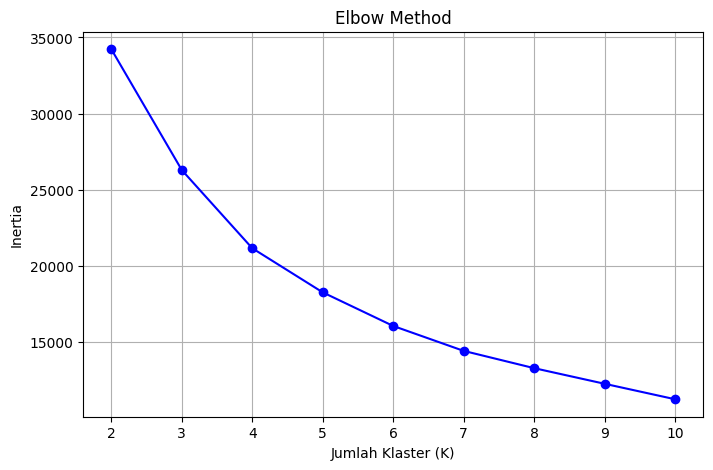

K=2 -> Silhouette Score = 0.3132
K=3 -> Silhouette Score = 0.3214
K=4 -> Silhouette Score = 0.3362
K=5 -> Silhouette Score = 0.2825
K=6 -> Silhouette Score = 0.2837
K=7 -> Silhouette Score = 0.2938
K=8 -> Silhouette Score = 0.3015
K=9 -> Silhouette Score = 0.3075
K=10 -> Silhouette Score = 0.3166

K optimal berdasarkan Silhouette tertinggi: 4
[OK] Hasil clustering disimpan: earthquakes_clustered.csv
cluster
1    4850
0    1996
2    1470
3    1010
Name: count, dtype: int64


In [5]:
# step4_clustering
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv('D:\Clustering menggunakan K-Means\Alma_Test3_ClusteringK-Means.csv')
fitur_scaled = ['latitude_scaled', 'longitude_scaled', 'depth_scaled', 'mag_scaled', 'sig_scaled']
X = df[fitur_scaled].values

# ---------- 4.1 Elbow Method ----------
inertia = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertia, 'bo-')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.grid(True)
plt.savefig('output_elbow.png', dpi=100)
plt.show()

# ---------- 4.2 Silhouette Score tiap K ----------
sil_scores = []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    sil_scores.append(silhouette_score(X, labels))
    print(f"K={k} -> Silhouette Score = {sil_scores[-1]:.4f}")

# Pilih K = 4 (misal), atau otomatis K dengan silhouette tertinggi:
best_k = list(K_range)[int(np.argmax(sil_scores))]
print(f"\nK optimal berdasarkan Silhouette tertinggi: {best_k}")

# ---------- 4.3 Jalankan KMeans final ----------
K_FINAL = 4    # bisa ganti best_k
kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Simpan model
joblib.dump(kmeans, 'kmeans_model.pkl')

# ---------- 4.4 Simpan hasil klaster ----------
df.to_csv('earthquakes_clustered.csv', index=False)
print(f"[OK] Hasil clustering disimpan: earthquakes_clustered.csv")
print(df['cluster'].value_counts())

In [6]:
# step5_evaluation
import pandas as pd
from sklearn.metrics import silhouette_score

df = pd.read_csv('D:\Clustering menggunakan K-Means\earthquakes_clustered.csv')
fitur_scaled = ['latitude_scaled', 'longitude_scaled', 'depth_scaled', 'mag_scaled', 'sig_scaled']
X = df[fitur_scaled].values
labels = df['cluster'].values

# 5.1 Metrik
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=df['cluster'].nunique(), random_state=42, n_init=10)
kmeans.fit(X)
inertia = kmeans.inertia_
sil = silhouette_score(X, labels)
print("=" * 60)
print(f"Inertia         : {inertia:.4f}")
print(f"Silhouette Score: {sil:.4f}")
print("Interpretasi: inertia kecil -> klaster kompak; silhouette mendekati 1 -> klaster terpisah baik.")
print("=" * 60)

# 5.2 Karakteristik tiap klaster
fitur_asli = ['latitude', 'longitude', 'depth', 'mag', 'sig']
summary = df.groupby('cluster')[fitur_asli].mean().round(2)
summary['jumlah_anggota'] = df['cluster'].value_counts().sort_index()
print("\nKarakteristik rata-rata tiap klaster:")
print(summary)

summary.to_csv('cluster_summary.csv')

<>:5: SyntaxWarning: invalid escape sequence '\C'
<>:5: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\293075752.py:5: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\earthquakes_clustered.csv')


Inertia         : 21146.4290
Silhouette Score: 0.3362
Interpretasi: inertia kecil -> klaster kompak; silhouette mendekati 1 -> klaster terpisah baik.

Karakteristik rata-rata tiap klaster:
         latitude  longitude   depth   mag     sig  jumlah_anggota
cluster                                                           
0          -18.08     -88.72   19.08  4.73  344.84            1996
1           21.93     130.62   25.08  4.67  336.65            4850
2           11.56      75.09   28.53  5.37  447.21            1470
3           -4.73      53.71  128.01  4.69  340.19            1010


<>:6: SyntaxWarning: invalid escape sequence '\C'
<>:6: SyntaxWarning: invalid escape sequence '\C'
C:\Users\user\AppData\Local\Temp\ipykernel_2784\4037374089.py:6: SyntaxWarning: invalid escape sequence '\C'
  df = pd.read_csv('D:\Clustering menggunakan K-Means\earthquakes_clustered.csv')


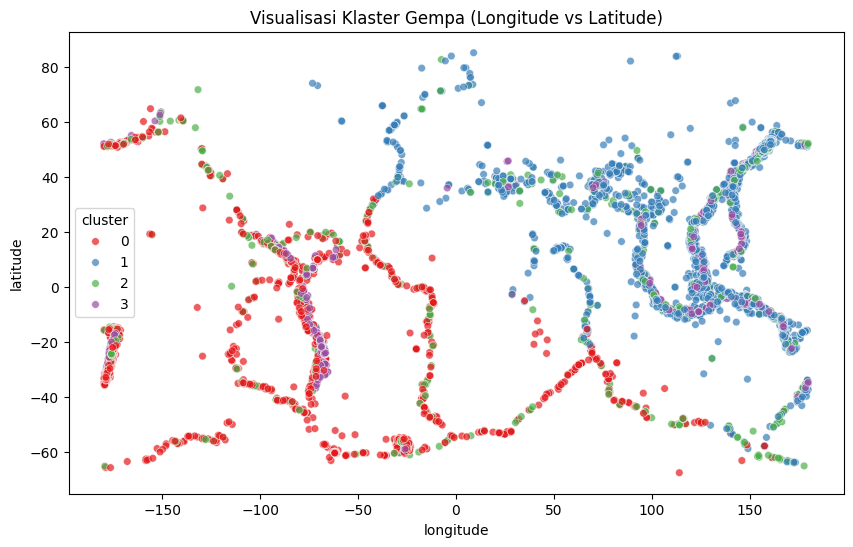

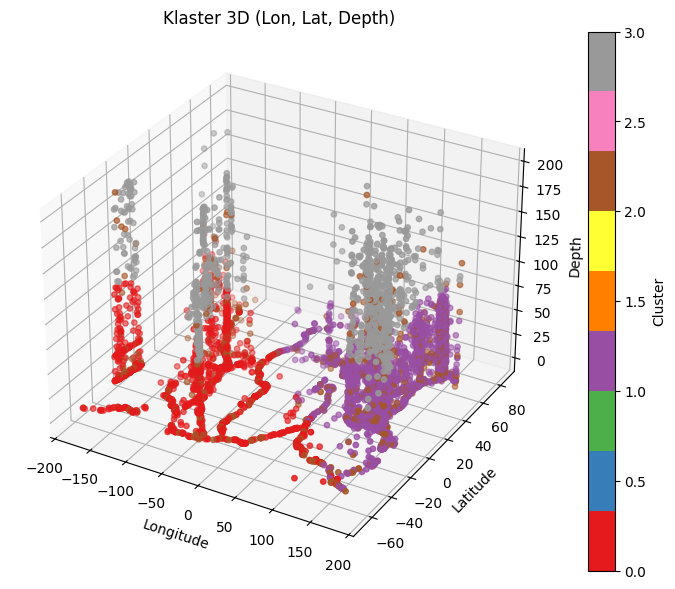

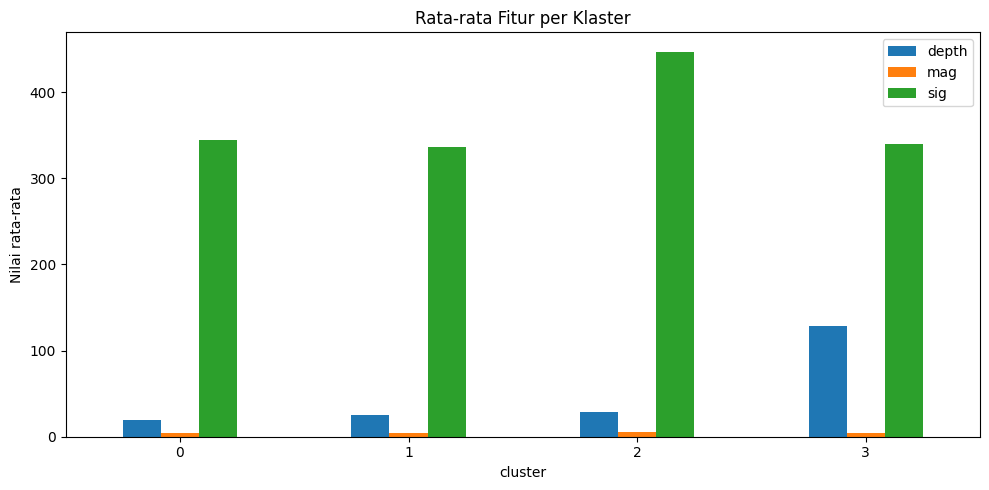

In [7]:
# step6_visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('D:\Clustering menggunakan K-Means\earthquakes_clustered.csv')

# 6.1 Scatter 2D (longitude vs latitude)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='longitude', y='latitude',
                hue='cluster', palette='Set1', s=30, alpha=0.7)
plt.title('Visualisasi Klaster Gempa (Longitude vs Latitude)')
plt.savefig('output_cluster_map.png', dpi=100)
plt.show()

# 6.2 Scatter 3D (longitude, latitude, depth)
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['longitude'], df['latitude'], df['depth'],
                c=df['cluster'], cmap='Set1', s=15)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_zlabel('Depth')
ax.set_title('Klaster 3D (Lon, Lat, Depth)')
plt.colorbar(sc, label='Cluster')
plt.savefig('output_cluster_3d.png', dpi=100)
plt.show()

# 6.3 Bar chart rata-rata fitur tiap klaster
summary = df.groupby('cluster')[['depth','mag','sig']].mean()
summary.plot(kind='bar', figsize=(10,5))
plt.title('Rata-rata Fitur per Klaster')
plt.ylabel('Nilai rata-rata')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('output_cluster_bar.png', dpi=100)
plt.show()

# 6.4 Elbow Curve (sudah dibuat di step4)
# 6.5 Silhouette Score per K